In [ ]:
# Paquetes requeridos

## Trabajar con rutas absolutas y recrear el comportamiento de setwd() de R
from pathlib import Path
import os

## Librería para trabajar vectores y matrices en python
import numpy as np

## Procesamiento de datos
import pandas as pd

## Librería de graficación en python
import matplotlib.pyplot as plt

## Bibliotecas para el trabajo de series de tiempo en python
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller

# Define el directorio de trabajo sobre el cual va a trabajar
project_path = Path(r"C:\Users\ngord\OneDrive\Escritorio\talleres aplicados econometria 2\talleres_aplicados-main\parcial2\taller_VAR\python")
os.chdir(project_path)

## Librerias que complementan la libreria de graficacion matplotlib
## (Se usan en la graficacion de las IRF)
from funciones_auxiliares_graficacion_VAR import (
    configurar_entorno_graficas,
    graficar_grilla_irf,
    graficar_pronostico_var,
    graficar_ts,
    imprimir_adf,
    imprimir_matrices_acof,
    imprimir_seleccion_rezagos,
    mostrar_graficas,
    predecir_var,
    prueba_arch_por_ecuacion,
    prueba_normalidad_por_ecuacion,
)

configurar_entorno_graficas(max_columns=30)

# Importe la base de datos desde Excel
datos = pd.read_excel("datos_VAR.xlsx")

In [ ]:
datos.head()

,x,y
0,-1.801254,-0.608943
1,1.789409,1.714214
2,1.442713,0.770903
3,0.006415,0.115383
4,-1.042136,-0.730270


In [ ]:
# Ahora bien, asuma lo siguiente que la variable "y" es la "variable mas exogena" de las dos variables que se van a modelar, es decir:

## 1) Un shock en "y" afecta de manera inmediata/contemporanea (es decir, desde el periodo t que ocurre el shock) tanto a "x" como a si mismo ("y").
## 2) Mientras que un shock en "x" unicamente afecta de manera inmediata/contemporanea (es decir, desde el periodo t que ocurre el shock) a si mismo ("x")
##    y es en periodos posteriores a t que afecta la variable y.

# Use la informacion anterior, para organizar de manera correcta las variables que conforman la base de datos que importo en Python,
# de tal forma que estas queden en el orden correcto para calcular las funciones impulso respuesta ortogonalizadas usando la
# descomposicion de Cholesky:
datos = datos.loc[:, ["y", "x"]]

# verifique que el orden de sus variables en su base de datos haya quedado en el orden correcto
datos.info()
print(datos.head())

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       600 non-null    float64
 1   x       600 non-null    float64
dtypes: float64(2)
memory usage: 9.5 KB
          y         x
0 -0.608943 -1.801254
1  1.714214  1.789409
2  0.770903  1.442713
3  0.115383  0.006415
4 -0.730270 -1.042136


In [ ]:
# Cree el índice temporal 
tiempo = pd.period_range(
    start="1990Q1",
    periods=len(datos),
    freq="Q",
    name="tiempo",
)

# Cree el pandas dataframe con índice temporal
series = pd.DataFrame(
    datos.to_numpy(),
    index=tiempo,
    columns= datos.columns,
)

In [ ]:
series.head()

,y,x
tiempo,,
1990Q1,-0.608943,-1.801254
1990Q2,1.714214,1.789409
1990Q3,0.770903,1.442713
1990Q4,0.115383,0.006415
1991Q1,-0.730270,-1.042136


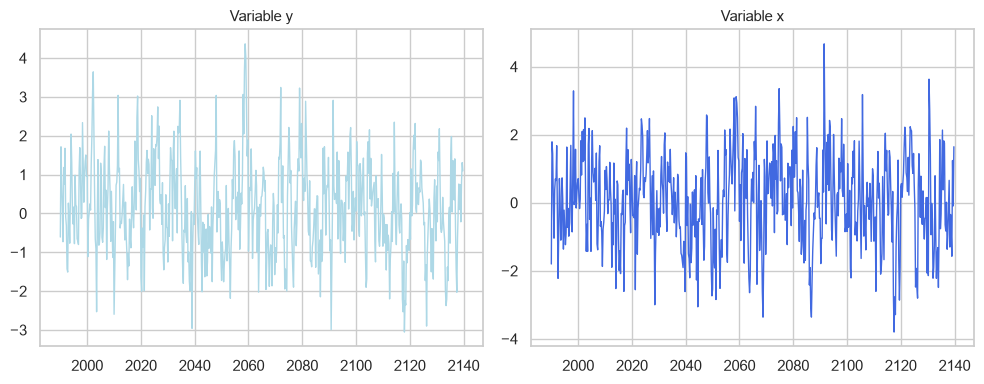

In [ ]:
fig_series, axes_series = plt.subplots(1, 2, figsize=(10, 4))

graficar_ts(
    series.iloc[:, 0],
    titulo="Variable y",
    color="lightblue",
    ax=axes_series[0],
)

graficar_ts(
    series.iloc[:, 1],
    titulo="Variable x",
    color="royalblue",
    ax=axes_series[1],
)

fig_series.tight_layout()
mostrar_graficas()

In [ ]:
# Para los parametros de la prueba de Dickey-Fuller, use las siguientes especificaciones: " maxlag=3, autolag='AIC', regression='n' "

## Prueba de ADF para la priemra serie de tiempo
adf1 = adfuller( series.iloc[:, 0], maxlag=3, autolag="AIC", regression="n")
imprimir_adf(adf1, "y") 

## Prueba de ADF para la segunda serie de tiempo
adf2 = adfuller( series.iloc[:, 1], maxlag=3, autolag="AIC", regression="n")
imprimir_adf(adf2, series.columns[1]) 


ADF para y
Estadistico ADF: -10.258883
p-valor: 0.000000
Rezagos usados: 1
Valores criticos:
  1%: -2.569489
  5%: -1.941458
  10%: -1.616383

ADF para x
Estadistico ADF: -14.898872
p-valor: 0.000000
Rezagos usados: 0
Valores criticos:
  1%: -2.569483
  5%: -1.941458
  10%: -1.616384


In [ ]:
# Nombre de las series de tiempo individuales
variables = list(series.columns)

# Para crear el objeto VAR con statsmodels quitamos el indice temporal y
# dejamos solo los datos. El indice trimestral se conserva en series para
# graficas y tablas.
series_modelo = series.reset_index(drop=True)

In [ ]:
# Creación del objeto de tipo statsmodels.tsa.vector_ar.var_model.VAR 
modelo_var = VAR(series_modelo)

# Seleccion de rezagos para un VAR
seleccion_rezagos = modelo_var.select_order(maxlags=6, trend="n")
imprimir_seleccion_rezagos(
    seleccion_rezagos,
    "Seleccion de rezagos para un VAR sin terminos deterministicos",
    incluir_rezago_cero=False,
)


Seleccion de rezagos para un VAR sin terminos deterministicos
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0    0.002249     0.03179       1.002     0.01375
1   0.009844*    0.06893*      1.010*    0.03285*
2     0.02239      0.1110       1.023     0.05690
3     0.02844      0.1466       1.029     0.07446
4     0.03731      0.1850       1.038     0.09484
5     0.04012      0.2174       1.041      0.1091
-------------------------------------------------


In [ ]:
VAR_estimado = modelo_var.fit(1, trend="n")

# ¿Cuales son las raices del polinomio asociado a la parte autoregresiva del modelo VAR det(I - A(L)), donde A(L) denota la parte autoregresiva del VAR?
# Ojo, tenga mucho cuidado con lo que se le esta preguntando!!!
# Nota: En statsmodels las raices reportadas por roots deben quedar por fuera
#       del circulo unitario. Adicionalmente, is_stable() revisa que los valores
#       propios de la matriz de compania queden dentro del circulo unitario.
raices_var = pd.DataFrame(
    {
        "raiz": VAR_estimado.roots,
        "modulo": np.abs(VAR_estimado.roots),
    }
)
print(raices_var)
print("El proceso es estable:", VAR_estimado.is_stable(verbose=True))

# ¿Cuales son los coeficientes del modelo?

# Nota: Bcoef y Acoef difererian si por ejemplo el VAR tuviera terminos determinisitcos (e.g. constantes, tendencias lineales deterministicas y demas)

## Para visualizar todos los coeficientes
Bcoef_VAR_estimado = VAR_estimado.params.T
print(Bcoef_VAR_estimado)

## Para visualizar solo los coeficientes asosicados a los rezagos del modelo VAR
imprimir_matrices_acof(VAR_estimado , variables)

# Resumen completo de los resultados de la estimacion del VAR
print( VAR_estimado.summary())

       raiz    modulo
0  3.571339  3.571339
1  1.662601  1.662601
Eigenvalues of VAR(1) rep
0.6014672287239903
0.280007004146658
El proceso es estable: True
       L1.y      L1.x
y  0.517412  0.113388
x  0.175991  0.364063

Matriz A_1
       L1.y      L1.x
y  0.517412  0.113388
x  0.175991  0.364063
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 20, Nov, 2026
Time:                     21:22:15
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                  0.0344624
Nobs:                     599.000    HQIC:                 0.0165382
Log likelihood:          -1697.42    FPE:                    1.00512
AIC:                   0.00511173    Det(Omega_mle):        0.998446
--------------------------------------------------------------------
Results for equation y
          coefficient       std. error           t-stat            prob
---------------

In [ ]:
# Residuales del modelo VAR estimado
residuales_var = pd.DataFrame(
    np.asarray( VAR_estimado.resid),
    index=series.index[ VAR_estimado.k_ar :],
    columns=variables,
)

# Test de no correlacion serial
P_10 = VAR_estimado.test_whiteness(nlags=10, adjusted=False)
print(P_10.summary())

# Test de heterocedasticidad
# statsmodels no tiene un equivalente directo a arch.test() multivariado de
# vars en R. Por tanto, se construye una funcion que permite hacer un arch.test()
# univariado para cada uno de los residuales de la regresion, uno por cada
# variable del VAR.
arch_12 = prueba_arch_por_ecuacion(residuales_var, lags=12, variables=variables)
print(arch_12)

# Test de normalidad (Jarque-Bera para series multivariadas)
normalidad_var =  VAR_estimado.test_normality()
print(normalidad_var.summary())

normalidad_univariada = prueba_normalidad_por_ecuacion(
    residuales_var,
    variables=variables,
)
print(normalidad_univariada)

Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 10 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         26.42          51.00   0.879 36
----------------------------------------

Pruebas ARCH univariadas con 12 rezagos
y: LM p-value = 0.283095; F p-value = 0.284380
x: LM p-value = 0.226572; F p-value = 0.227052
            lm_stat  lm_pvalue    f_stat  f_pvalue
variable                                          
y         14.281496   0.283095  1.192788  0.284380
x         15.278228   0.226572  1.278259  0.227052
normality (skew and kurtosis) test. H_0: data generated by normally-distributed process. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
        0.6609          9.488   0.956  4
----------------------------------------

Pruebas Jarque-Bera univariada

$y
            fcst     lower     upper        CI
tiempo                                        
2140Q1  0.753677 -1.155525  2.662879  1.909202
2140Q2  0.479740 -1.742145  2.701625  2.221885
2140Q3  0.295948 -2.030565  2.622461  2.326513
2140Q4  0.180075 -2.183672  2.543822  2.363747
2141Q1  0.108890 -2.268288  2.486067  2.377178
2141Q2  0.065656 -2.316381  2.447693  2.382037
2141Q3  0.039535 -2.344260  2.423331  2.383795
2141Q4  0.023792 -2.360640  2.408224  2.384432
2142Q1  0.014314 -2.370349  2.398976  2.384662
2142Q2  0.008610 -2.376135  2.393356  2.384746
2142Q3  0.005179 -2.379597  2.389955  2.384776
2142Q4  0.003115 -2.381672  2.387902  2.384787

$x
            fcst     lower     upper        CI
tiempo                                        
2140Q1  0.791787 -1.503676  3.087249  2.295462
2140Q2  0.420900 -2.099303  2.941103  2.520203
2140Q3  0.237664 -2.343371  2.818698  2.581035
2140Q4  0.138609 -2.462321  2.739538  2.600930
2141Q1  0.082154 -2.525708  2.690015  2.607862
2141Q2

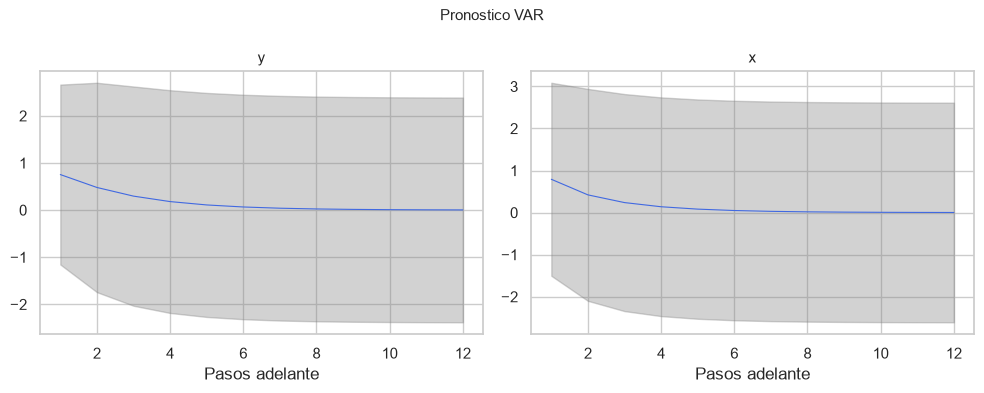

In [ ]:
# Pronóstico
pronostico_var = predecir_var(
    VAR_estimado,
    n_ahead=12,
    ci=0.95,
    indice=series.index,
    variables=variables,
)
print(pronostico_var)

# Gráfica del pronóstico
fig_pronostico, axes_pronostico = graficar_pronostico_var(
    pronostico_var["pronostico"],
    pronostico_var["inferior"],
    pronostico_var["superior"],
)
fig_pronostico.suptitle("Pronostico VAR", fontsize=11)
fig_pronostico.tight_layout()
mostrar_graficas()

[[[1.         0.        ]
  [0.         1.        ]]

 [[0.51741152 0.11338796]
  [0.17599051 0.36406271]]

 [[0.28766989 0.09994856]
  [0.1551311  0.15249686]]

 [[0.16643371 0.06900585]
  [0.10710462 0.07310842]]

 [[0.09825909 0.04399403]
  [0.06828355 0.03876042]]

 [[0.05858292 0.02715799]
  [0.04215216 0.02185376]]

 [[0.03509103 0.01652981]
  [0.02565607 0.01273569]]

 [[0.02106559 0.00999679]
  [0.01551611 0.00754568]]

 [[0.01265892 0.00602804]
  [0.00935618 0.00450644]]

 [[0.00761075 0.00362995]
  [0.00563409 0.0027015 ]]

 [[0.00457673 0.0021845 ]
  [0.00339058 0.00162235]]]
[[[0.97410031 0.        ]
  [0.56516045 1.02579051]]

 [[0.56809311 0.11631229]
  [0.37718626 0.37345208]]

 [[0.3367063  0.10252629]
  [0.23729845 0.15642983]]

 [[0.20112251 0.07078554]
  [0.14564863 0.07499392]]

 [[0.1205779  0.04512866]
  [0.08842089 0.03976007]]

 [[0.07241426 0.0278584 ]
  [0.05341132 0.02241738]]

 [[0.04352417 0.01695612]
  [0.03218929 0.01306415]]

 [[0.02616979 0.01025461]
  

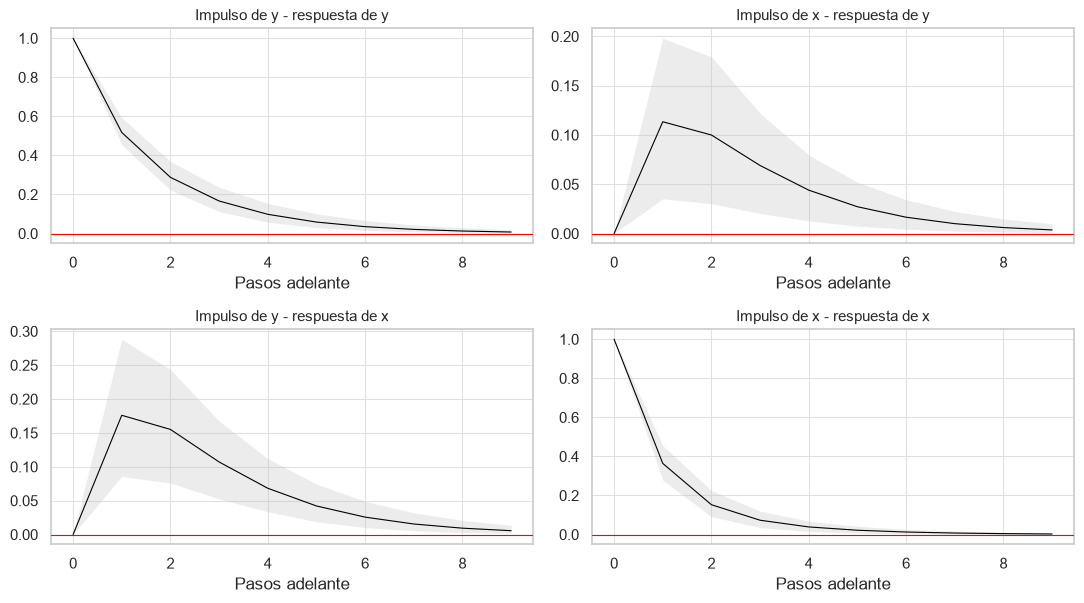

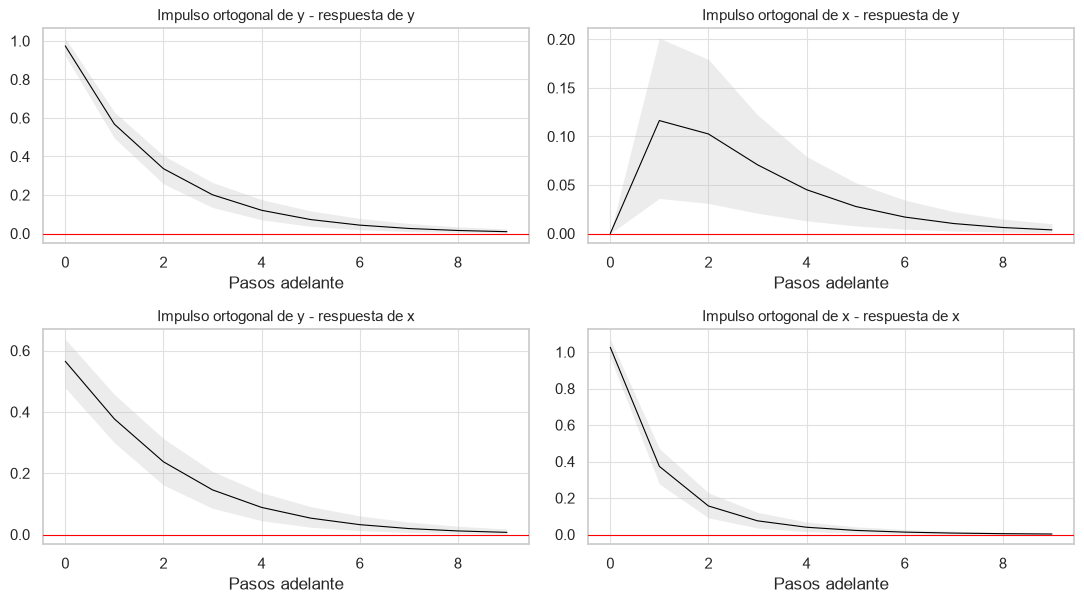

In [ ]:
# Matrices asociadas a las funciones impulso respuesta
print( VAR_estimado.irf().irfs)

# Matrices asociadas a las funciones impulso respuesta ortogonalizadas
print( VAR_estimado.irf().orth_irfs)

# Cargue las funciones auxiliares para graficar las IRF
# En Python estas funciones se importaron al inicio desde
# funciones_auxiliares_graficacion_VAR.py.

# Parametros de las graficas de las IRF
variables = list(series.columns)
pasos_adelante = np.arange(0,10 )
int_conf_irf = 0.95
semilla_irf = 202601
repeticiones_bootstrap_irf = 100 # Bootstrappings empleados para construir los IC de las IRF

# La funcion graficar_grilla_irf() calcula el objeto irf() una sola vez
# y luego crea cada panel con programacion funcional.

# Graficacion de las IRF no ortogonalizadas

# IRF de las variables del sistema ante distintos choques exogenos.
irf_no_ortog = graficar_grilla_irf(
    VAR_estimado,
    variables,
    pasos_adelante,
    ortog=False,
    int_conf=int_conf_irf,
    prefijo_titulo="Impulso",
    semilla=semilla_irf,
    runs=repeticiones_bootstrap_irf,
)

# Grilla de IRF: columnas = impulsos; filas = respuestas.
mostrar_graficas()

# Graficacion de las IRF ortogonalizadas

# Usamos los mismos pasos adelante, intervalo de confianza y semilla.
# IRF ortogonalizadas de las variables del sistema ante distintos choques exogenos.
irf_ortog = graficar_grilla_irf(
    VAR_estimado,
    variables,
    pasos_adelante,
    ortog=True,
    int_conf=int_conf_irf,
    prefijo_titulo="Impulso ortogonal",
    semilla=semilla_irf,
    runs=repeticiones_bootstrap_irf,
)

# Grilla de OIRF: columnas = impulsos; filas = respuestas.
mostrar_graficas()